# 05 · Alt/BTC ratio mean reversion

This notebook tests one trading idea from start to finish:

> **When an altcoin gets unusually cheap or unusually expensive compared with Bitcoin, bet that it moves back to normal.**

**Short answer: it does not work.** After costs the strategy lost a little money on the test period. Section 8 has the numbers and section 10 explains why.

The notebook itself only explains and plots. All calculations live in `src/`, and all settings come from `config_ratio.yaml`. The settings were chosen using the older "train" data only (section 7 shows how).

*Before running:* run `python src/data.py config_ratio.yaml` once. It downloads the daily prices into `data/`.

### The idea in plain words

**1. Price each altcoin in Bitcoin instead of dollars.** Divide the altcoin's price by Bitcoin's price. If ETH costs \$3,000 and BTC costs \$60,000, then ETH/BTC = 0.05, so one ETH is worth 0.05 BTC.
- The ratio **rises** when ETH does better than BTC and **falls** when ETH does worse.
- When the whole crypto market goes up or down together, the ratio mostly stays put. It only measures *ETH compared with BTC*.

**2. Bet that the ratio returns to normal.** "Normal" means the ratio's average over the last 90 days. The bet that prices drift back to their average is called **mean reversion**.
- Ratio far **above** normal: the alt is expensive in BTC terms, so **sell the alt and buy BTC**.
- Ratio far **below** normal: the alt is cheap, so **buy the alt and sell BTC**.
- Ratio **back at normal**: close both positions and keep the profit.

**3. Always trade both coins for the same dollar amount.** If crypto as a whole crashes 20%, the coin we own and the coin we sold both fall, and the two losses roughly cancel. We only win or lose on the *gap between the two coins*. This is called a **pair trade** (also *market-neutral* or *relative-value* trade).

### Key terms

| Term | Meaning |
|---|---|
| Alt / altcoin | Any cryptocurrency other than Bitcoin |
| Long / short | **Long** = you own it and profit if the price rises. **Short** = you borrowed it and sold it, so you profit if the price falls |
| Leg | One side of a pair trade. Every trade has an alt leg and a BTC leg |
| Ratio | Alt price ÷ BTC price |
| Log ratio | The natural log of the ratio. Same information, but a doubling and a halving count as equally large moves, which keeps the maths symmetric |
| Rolling mean | The average over the last N days, recalculated every day |
| Standard deviation (std) | How far the ratio typically wanders from its average: the size of a "normal wiggle" |
| z-score | How far from normal the ratio is today, measured in normal wiggles: `z = (today − average) / std`. z = +2 means two wiggles above normal, which is unusual |
| Half-life | How long it takes for half of a gap to close (section 2) |
| Train / test | **Train** = older data (2018–2022), used to design and tune the strategy. **Test** = newer data (2023–2026), used once at the end as an honest check |
| Backtest | Simulating the strategy on historical prices as if it had been traded |
| Notional | The dollar size of a position |
| bps (basis points) | 1 bp = 0.01%. So 10 bps = 0.1% |
| Sharpe ratio | Yearly return divided by yearly volatility. Higher is better, and negative means the strategy lost money |
| Drawdown | How far the account fell from its highest value so far |

In [1]:
import sys
import warnings
from pathlib import Path

# Make the repo root importable, whether Jupyter starts in notebooks/ or the repo root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd

from src import data, strategy, backtest, plots

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
plots.apply_style()

cfg = data.load_config("config_ratio.yaml")
setup, params = cfg["setup"], cfg["parameters"]
BTC = data.coin_name(setup["numeraire"])

## 0. Load the data and run the strategy once

This cell does the heavy lifting up front. Every section below just reads from its results.

1. Load the daily closing prices (`data.load_daily_prices`).
2. Split them into a **train** period and a **test** period.
3. Measure the things that need history, such as how fast each ratio returns to normal and how much it swings. This uses **train data only** (`backtest.calibrate_pairs`), so the test period stays unseen.
4. Run the strategy on both periods (`backtest.run_ratio_portfolio`).

In [2]:
prices = data.load_daily_prices(cfg)
train, test = data.split_train_test(prices, setup["train_end"])
calibration = backtest.calibrate_pairs(cfg, prices)

train_result, train_pairs = backtest.run_ratio_portfolio(cfg, prices, "train")
test_result, test_pairs = backtest.run_ratio_portfolio(cfg, prices, "test")

print(f"prices: {prices.index[0]:%Y-%m-%d} -> {prices.index[-1]:%Y-%m-%d}, {len(prices)} days, {prices.shape[1]} coins")
for period in ("train", "test"):
    start, end = backtest.period_bounds(cfg, period)
    print(f"{period:5s}: {start:%Y-%m-%d} -> {end:%Y-%m-%d} (end exclusive)")

prices: 2017-11-09 -> 2026-10-31, 3279 days, 11 coins
train: 2018-01-01 -> 2023-01-01 (end exclusive)
test : 2023-01-01 -> 2026-11-01 (end exclusive)


## 1. Which coins, and why

**Bitcoin is the reference coin.** All other prices are measured in BTC. The config calls it the *numeraire*, which just means "the unit you measure in".

**Ten large altcoins are paired against it.** We started from big coins that trade on every major exchange. The deciding requirement was **a complete price history back to late 2017**, so that the train period contains a full crypto boom *and* crash.

| Alt | Why it is in |
|---|---|
| ETH | Largest alt, most traded. The cleanest case of a coin that follows BTC |
| BNB | Large exchange token, heavily traded on Binance |
| XRP | Top-5 coin for most of the sample, lots of retail trading |
| ADA | Large smart-contract platform, actively traded since 2017 |
| DOGE | Heavily traded but driven by hype: a deliberate stress test for "returns to normal" |
| LTC | One of the oldest alts, with a long BTC-like history |
| LINK | Largest "oracle" token, with active futures markets |
| BCH | A spin-off of Bitcoin, so economically the closest to BTC |
| XLM | Payments coin that often moves with XRP, traded since 2017 |
| TRX | Large coin with a long history that moves less in step with BTC |

**Left out:** SOL, AVAX and DOT are large too, but their Yahoo history only starts in 2020. Including them would halve the data and drop the 2018 crash from the train period.

**Data:** one closing price per day from Yahoo Finance (taken at 00:00 UTC, since crypto trades every day). `data.coverage_report` checks every coin for missing days. Short gaps of up to `max_ffill_days` would be filled with the previous day's price and longer gaps dropped. In this sample no days are missing.

In [3]:
data.coverage_report(cfg)

,first,last,n_days,missing_days,longest_gap,ffilled,unfilled
BTC,2017-11-09,2026-10-31,3279,0,0,0,0
ETH,2017-11-09,2026-10-31,3279,0,0,0,0
BNB,2017-11-09,2026-10-31,3279,0,0,0,0
XRP,2017-11-09,2026-10-31,3279,0,0,0,0
ADA,2017-11-09,2026-10-31,3279,0,0,0,0
DOGE,2017-11-09,2026-10-31,3279,0,0,0,0
LTC,2017-11-09,2026-10-31,3279,0,0,0,0
LINK,2017-11-09,2026-10-31,3279,0,0,0,0
BCH,2017-11-09,2026-10-31,3279,0,0,0,0
XLM,2017-11-09,2026-10-31,3279,0,0,0,0


Each coin's price in USD, all starting at 1. The scale is logarithmic, so a doubling looks the same size everywhere on the chart. All coins rise and fall together in the big crypto cycles, but by very different amounts. Those differences are exactly what moves the alt/BTC ratios.

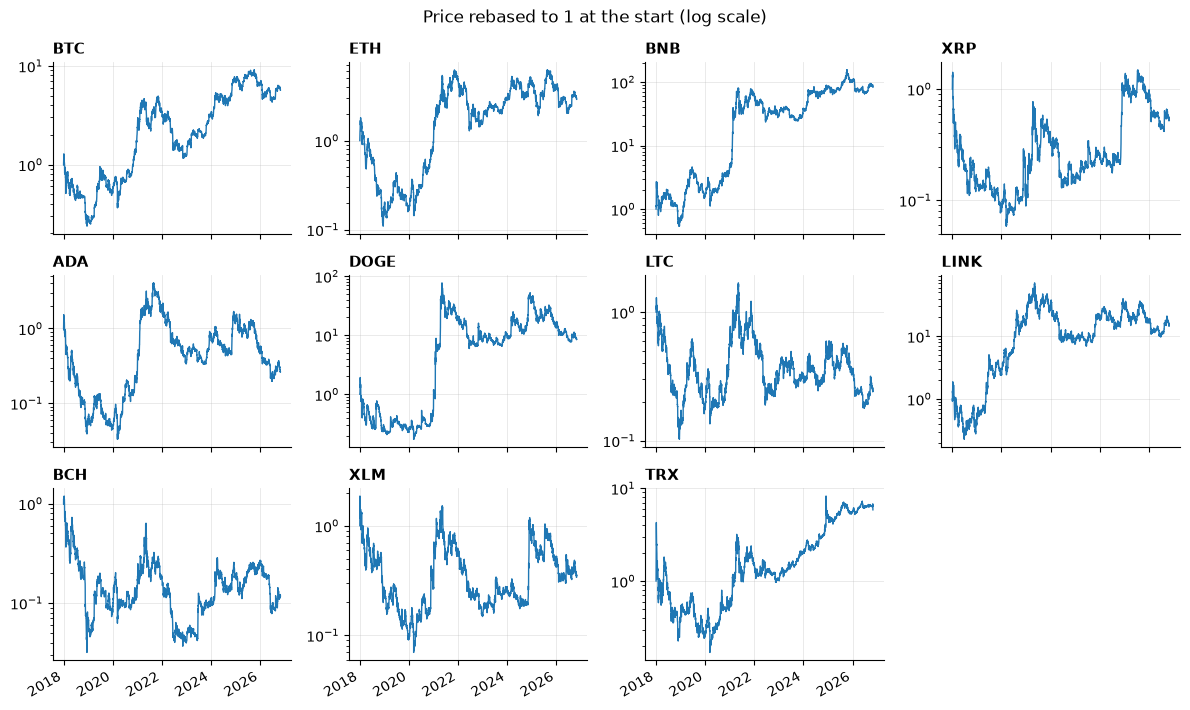

In [4]:
plots.plot_prices(prices.loc[setup["start"]:]);

**Do the coins move together?** The **correlation** of daily price changes on train data (`strategy.return_correlations`). 1 means two coins always move in the same direction, 0 means they are unrelated.

Every alt moves with BTC (0.5 to 0.8), which makes BTC a sensible coin to pair them against. But the numbers are far from 1, so each ratio still swings a lot on its own (section 3).

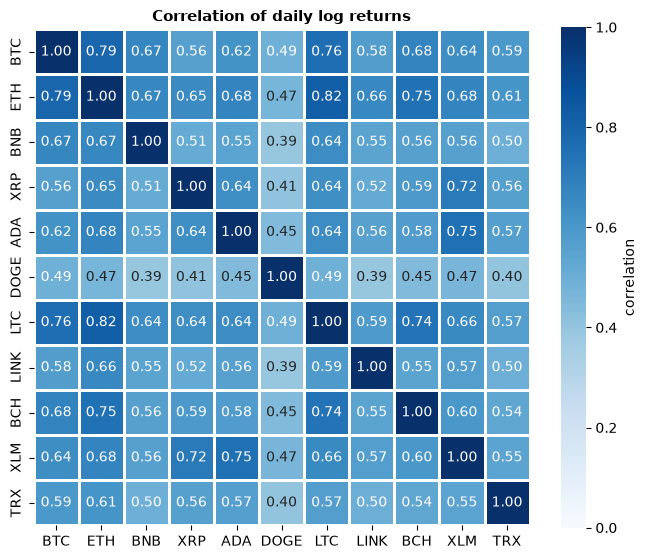

In [5]:
plots.plot_correlation_matrix(strategy.return_correlations(train));

## 2. How long does a trade last?

That depends on how fast a stretched ratio snaps back to normal, which we measure with the **half-life**: the number of days until half of the gap has closed.

> *Example:* the ratio is 10% above normal and the half-life is 30 days. After 30 days it is about 5% above, after 60 days about 2.5%, and so on. It never jumps straight back. It closes half of what is left in each half-life, like a hot cup of coffee cooling down.

**How it is measured.** `strategy.estimate_half_life` fits a simple model on train data called **AR(1)** ("autoregressive, one step back"). The model says:

$$\text{today's gap} = \varphi \times \text{yesterday's gap} + \text{random noise}$$

The data decides φ. For example, φ = 0.97 means each day keeps 97% of yesterday's gap, so 3% closes per day. The half-life follows directly: $h = \ln 0.5 / \ln \varphi$, which gives about 23 days for φ = 0.97. (φ = 1 would mean no pull back to normal at all.)

**Two versions, depending on what "normal" means:**

| Column | "Normal" means… | Half-life |
|---|---|---|
| `half_life_level` | one fixed average over all of history | hundreds of days: it barely comes back |
| `half_life_dev` | the **90-day rolling average**, which is what the strategy trades | **23 to 55 days** (3 to 8 weeks) |

So trades last **weeks**, not hours or months. This is often called *swing trading*.

**Time stop: when to give up.** If a trade has not worked after a while, we close it anyway. The rule is "close after `time_stop_halflives` = 3 half-lives, but never later than `max_holding_days` = 60 days". Three half-lives is 70 to 165 days here, which is always more than 60. So in practice the rule is simply: **close any trade that is still open after 60 days.**

In [7]:
calibration[["half_life_level", "half_life_dev"]].round(1)

,half_life_level,half_life_dev
ETH,405.0,46.5
BNB,319.6,54.8
XRP,229.1,41.2
ADA,199.7,49.0
DOGE,456.4,47.3
LTC,381.9,37.3
LINK,268.3,30.8
BCH,673.9,35.1
XLM,370.3,23.3
TRX,96.9,41.5


How often the strategy actually traded in the backtest (`backtest.trade_frequency`):

In [8]:
pd.DataFrame({
    "train": backtest.trade_frequency(train_result.trades, cfg, "train"),
    "test": backtest.trade_frequency(test_result.trades, cfg, "test"),
}).round(1)

,train,test
n_trades,175.0,138.0
trades_per_month,2.9,3.0
trades_per_pair_per_year,3.5,3.6
avg_holding_days,18.8,24.2
median_holding_days,13.0,18.0


## 3. What the strategy looks at

Every day, `strategy.ratio_features` computes these numbers for each pair. Each value uses **only data up to that day**, so there is no peeking into the future.

| Feature | What it is |
|---|---|
| ratio | Alt price ÷ BTC price: the alt's price in BTC |
| log ratio `r` | `ln(alt) − ln(BTC)`. Its daily change is (approximately) the daily profit per dollar of a "buy alt, sell BTC" trade |
| mean, std | The average of `r`, and the size of its normal wiggle, over the last 90 days (`zscore_lookback`) |
| z | `(r − mean) / std`: how many normal wiggles today's ratio is away from its average. **This is the trading signal** |
| fair value | `BTC price × exp(mean)`: what the alt would cost in USD if the ratio were exactly at its average |
| deviation | `alt price / fair value − 1`: how many % the alt is above (+) or below (−) that fair value |

We use the **log** ratio because it treats up and down moves the same way (a doubling and a halving are equally far from the start) and because it lines up with the profit of the trade.

The table below shows the first 8 days of the test period for ETH/BTC.

In [9]:
eth = strategy.ratio_features(prices["ETH"], prices[BTC], params["zscore_lookback"], params["zscore_method"])
eth.loc[setup["train_end"]:].head(8)

,ratio,log_ratio,mean,std,z,fair_value,deviation
date,,,,,,,
2023-01-01 00:00:00+00:00,0.072,-2.628,-2.630,0.042,0.047,1198.612,0.002
2023-01-02 00:00:00+00:00,0.073,-2.620,-2.629,0.041,0.208,1204.295,0.009
2023-01-03 00:00:00+00:00,0.073,-2.620,-2.628,0.040,0.204,1204.769,0.008
2023-01-04 00:00:00+00:00,0.075,-2.597,-2.627,0.040,0.751,1219.305,0.031
2023-01-05 00:00:00+00:00,0.074,-2.600,-2.626,0.040,0.652,1218.548,0.026
2023-01-06 00:00:00+00:00,0.075,-2.592,-2.625,0.039,0.841,1228.253,0.033
2023-01-07 00:00:00+00:00,0.075,-2.596,-2.624,0.039,0.716,1229.735,0.028
2023-01-08 00:00:00+00:00,0.075,-2.586,-2.623,0.038,0.960,1241.122,0.037


**What counts as "normal"?** There are two choices (`zscore_method`):

- **rolling** (used here): the average of the **last 90 days**. It follows the market as conditions change. The downside: if the ratio keeps drifting in one direction, the average drifts along with it, so the ratio never looks very stretched and a trend can go unnoticed.
- **expanding**: the average of **all history so far**. It is very stable, but if the market changes for good, the ratio can sit far away from it for years.

The chart shows the difference on ETH/BTC. The expanding average barely moves while the ratio halves and doubles.

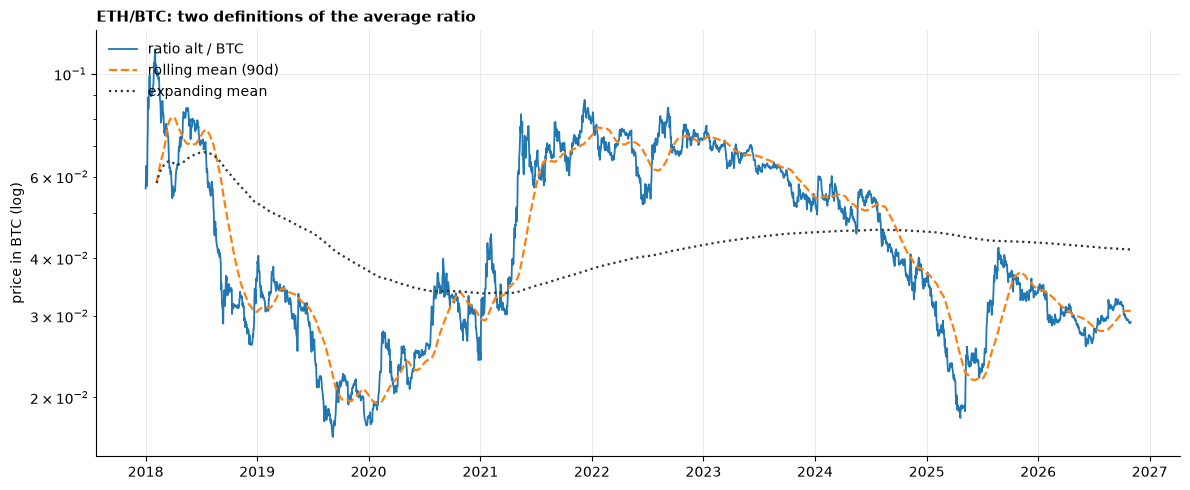

In [10]:
eth_expanding = strategy.ratio_features(prices["ETH"], prices[BTC], params["zscore_lookback"], "expanding")
plots.plot_mean_comparison(
    eth["ratio"].loc[setup["start"]:],
    {f"rolling mean ({params['zscore_lookback']}d)": eth["mean"].loc[setup["start"]:],
     "expanding mean": eth_expanding["mean"].loc[setup["start"]:]},
    title="ETH/BTC: two definitions of the average ratio",
);

**Does the choice matter?** Here is the strategy on the **train** period with each definition.

With the expanding average the strategy hardly trades: 12 trades instead of 175. Because that average includes every past trend, the "normal wiggle" (std) is very wide, and z rarely gets beyond ±2. For ETH this happened on only 17 train days, against 270 with the rolling average. And the few trades it does make bet on a return to a long-run average that, as the test below shows, these ratios do not actually return to.

In [11]:
expanding_train, _ = backtest.run_ratio_portfolio(cfg, prices, "train", {"zscore_method": "expanding"})
pd.DataFrame({"rolling (config)": train_result.metrics, "expanding": expanding_train.metrics}).loc[
    ["ann_return", "sharpe", "max_drawdown", "n_trades", "win_rate"]
]

,rolling (config),expanding
ann_return,-0.009,5.031e-05
sharpe,-0.079,1.064e-03
max_drawdown,-0.393,-9.084e-02
n_trades,175.000,1.200e+01
win_rate,0.486,5.000e-01


**Does the ratio really return to normal?** `strategy.pair_diagnostics` runs a statistical check on train data called the **ADF test**. It asks: "does this series get pulled back toward an average, or does it wander freely?" A p-value below 0.05 counts as evidence that it gets pulled back.

- `adf_level`: is the ratio pulled back to **one fixed long-run average**? For 9 of the 10 alts (all except TRX) the answer is **no** (p > 0.05). So betting that a ratio returns to its long-term average is not credible here.
- `adf_dev`: is the ratio pulled back to its **90-day rolling average**? Strongly yes. **But be careful:** subtracting a moving average makes almost *any* price series look like this, even pure random noise. So this number tells us *how long* trades will take, not whether they will make money.
- `ratio_vol`: how much the ratio swings per year, between 60% and 130%. Pairing with BTC removes the ups and downs of the overall crypto market, but most of the risk is still there.
- `corr_btc`: the correlation with BTC from section 1.

In [12]:
calibration[["corr_btc", "ratio_vol", "adf_level", "adf_dev"]]

,corr_btc,ratio_vol,adf_level,adf_dev
ETH,0.790,0.602,4.221e-01,2.681e-06
BNB,0.669,0.835,6.456e-02,6.541e-04
XRP,0.560,1.011,1.842e-01,5.043e-06
ADA,0.617,1.012,1.263e-01,1.388e-03
DOGE,0.492,1.304,5.789e-01,9.833e-04
LTC,0.760,0.688,6.508e-01,7.632e-04
LINK,0.575,1.107,2.632e-01,1.645e-04
BCH,0.682,0.900,6.705e-01,4.597e-04
XLM,0.637,0.903,4.714e-01,2.689e-06
TRX,0.594,1.074,1.523e-06,1.338e-04


## 4. When to buy and when to sell

The rules are in `strategy.generate_signals`. The extra safety exits are in `strategy.apply_risk` (section 6). With `entry_z = 2` and `exit_z = 0`:

| What happens to z | What it means | What we do |
|---|---|---|
| z rises above **+2** | the alt is expensive compared with BTC | **sell the alt, buy BTC**, same dollar amount |
| z falls below **−2** | the alt is cheap compared with BTC | **buy the alt, sell BTC**, same dollar amount |
| z crosses back to **0** | the ratio is back at normal | close both legs and take the profit (exit reason `mean`) |
| z jumps from one extreme to the other in a single day | the signal flips | close, and open the opposite trade the same day |

**Timing (no cheating with hindsight).** The signal on day *t* uses closing prices up to day *t*. The trade happens at the **next day's** close (`execution_lag = 1`). This is realistic: you can't decide on a price and trade at exactly that same price. Fees are charged when the trade happens.

In [13]:
print({k: params[k] for k in ("zscore_lookback", "zscore_method", "entry_z", "exit_z")})

{'zscore_lookback': 90, 'zscore_method': 'rolling', 'entry_z': 2.0, 'exit_z': 0.0}


**Example 1: ETH/BTC on the test period.** The shaded band is the 90-day average ± 2 normal wiggles. When the ratio leaves the band, a trade opens.

Markers: ▲ = buy the alt (ratio too low), ▼ = sell the alt (ratio too high), ✕ = close. They sit on the day the signal fired.

The second chart shows the same thing as a z-score: trades open when z leaves ±2 and close when z returns to 0.

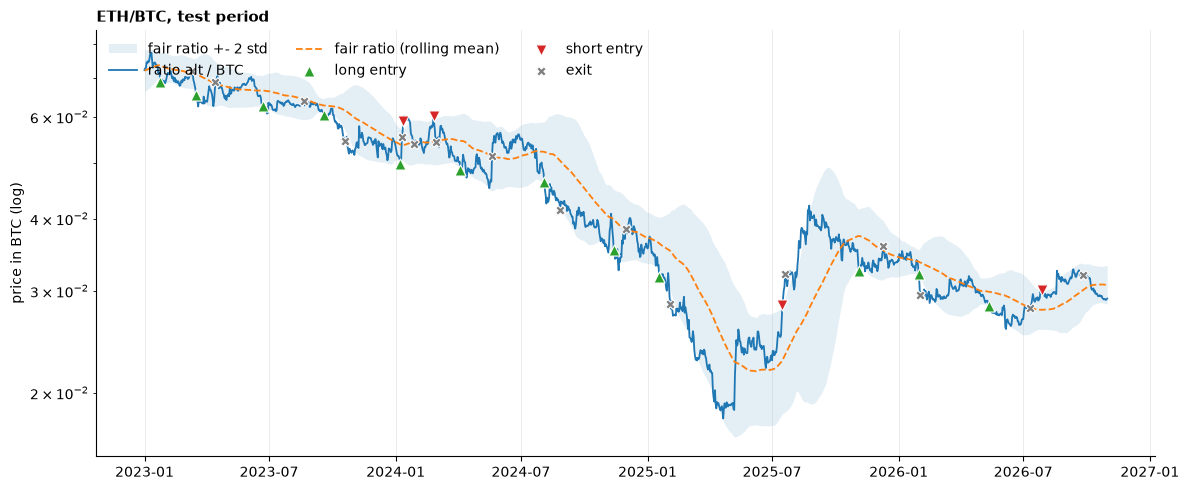

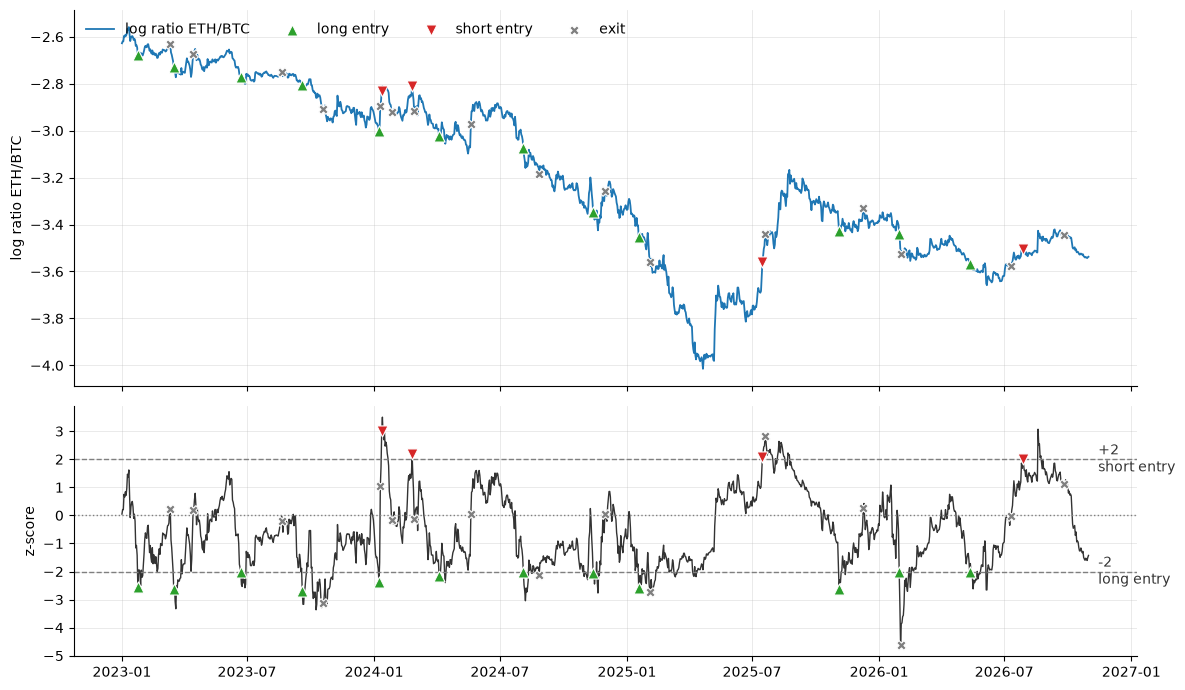

In [14]:
d = test_pairs["ETH"].daily
plots.plot_ratio_bands(d["ratio"], d["mean"], d["std"], params["entry_z"], d["position"], title="ETH/BTC, test period");
plots.plot_spread_zscore(d["log_ratio"].rename("log ratio ETH/BTC"), d["z"], d["position"], params["entry_z"], params["exit_z"]);

**Example 2: BCH/BTC**, the best pair in the test period, and **example 3: BNB/BTC**, the worst.

BNB kept getting cheaper against BTC: the ratio fell 38% over the test period. Every "BNB looks cheap, buy it" signal came too early because it just kept getting cheaper. All 5 of those trades lost money and were closed by the stop-loss or the time stop. ETH/BTC above shows the same pattern: a ratio that falls for two years produces a string of losing buys.

This is the main way mean reversion fails: **a steady trend looks like a bargain, again and again.**

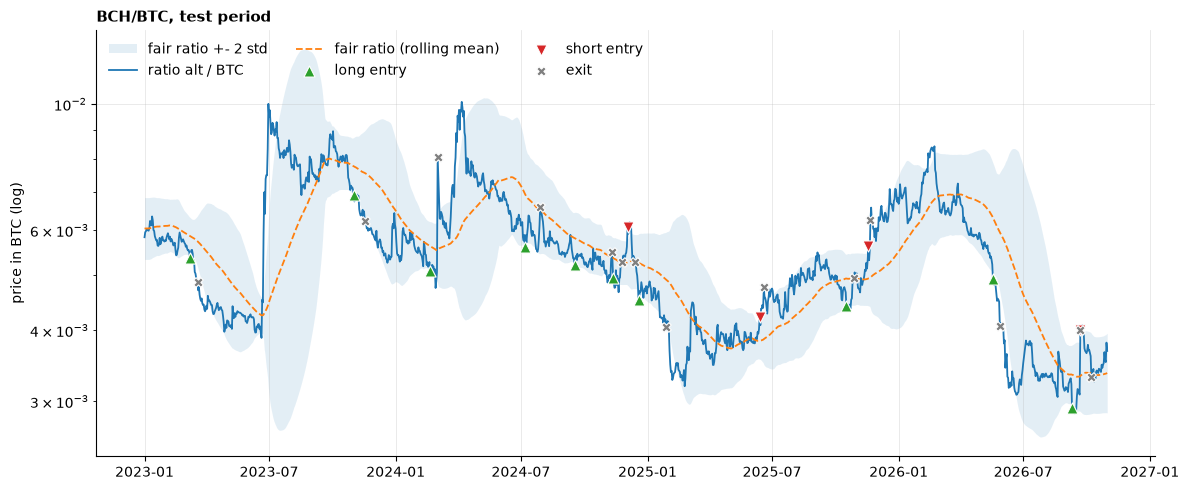

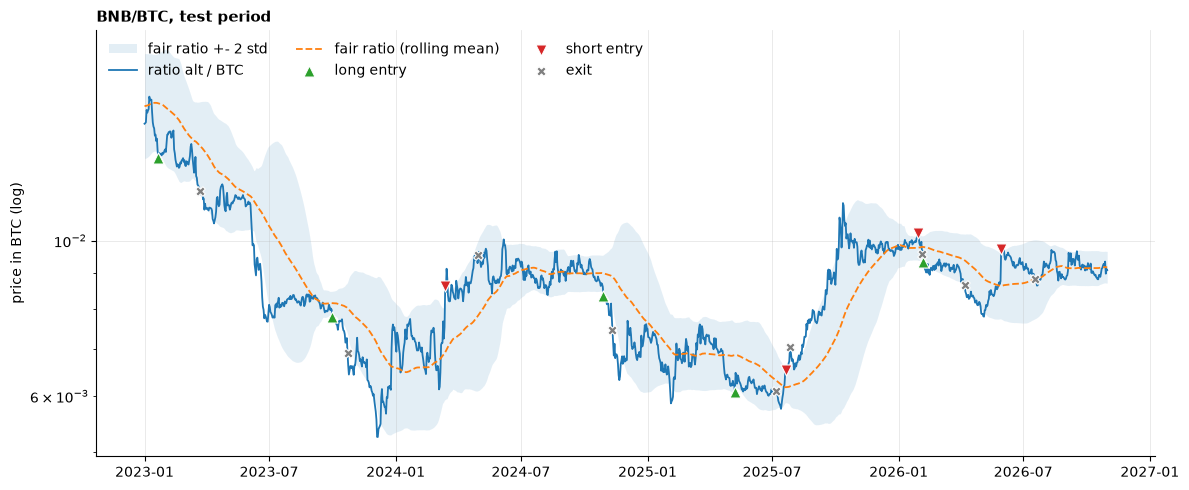

In [15]:
for alt in ("BCH", "BNB"):
    d = test_pairs[alt].daily
    plots.plot_ratio_bands(d["ratio"], d["mean"], d["std"], params["entry_z"], d["position"], title=f"{alt}/BTC, test period");

## 5. How big is each trade?

- **Equal dollars on both sides.** Each trade buys and sells the same dollar amount, for example buy \$5,000 of ETH and sell \$5,000 of BTC. If all of crypto drops 20%, the two legs roughly cancel, and we only gain or lose on ETH compared with BTC. Buying the alt on its own would mostly be a bet on crypto going up.
- **Wilder pairs get smaller positions** (`strategy.equal_risk_sizes`). Position size is proportional to `1 / ratio_vol`, with volatility measured on train data. DOGE's ratio swings about 130% a year and ETH's about 60%, so DOGE gets about half the size. That way each pair carries roughly the same risk.
- **Leverage cap.** Sizes are scaled so that if all 10 pairs are open at once, the total size of all legs (buys + sells) is exactly `max_gross_leverage` = 2× the capital. With \$100,000 that means at most \$200,000 of positions in total. Because that already covers the worst case, all 10 pairs are allowed to be open at the same time.
- **Fixed sizes, no reinvesting.** Sizes are a fraction of the *starting* capital and don't grow with profits (no compounding). The backtest also assumes each leg keeps a constant dollar size while the trade is open. In reality that needs small daily adjustments, and their cost is not charged (see section 10).
- **BTC legs are not combined.** If one pair buys BTC and another sells BTC, in reality they would partly cancel. The backtest counts both, which is the cautious choice.

Below: each pair's risk-based size, then the total exposure over the test period, which never goes above the 2× cap.

In [17]:
calibration[["ratio_vol", "size"]].assign(notional_per_leg=calibration["size"] * setup["initial_capital"]).round(3)

,ratio_vol,size,notional_per_leg
ETH,0.602,0.150,14958.632
BNB,0.835,0.108,10782.374
XRP,1.011,0.089,8901.317
ADA,1.012,0.089,8892.269
DOGE,1.304,0.069,6900.406
LTC,0.688,0.131,13084.039
LINK,1.107,0.081,8131.401
BCH,0.900,0.100,10001.232
XLM,0.903,0.100,9967.166
TRX,1.074,0.084,8381.165


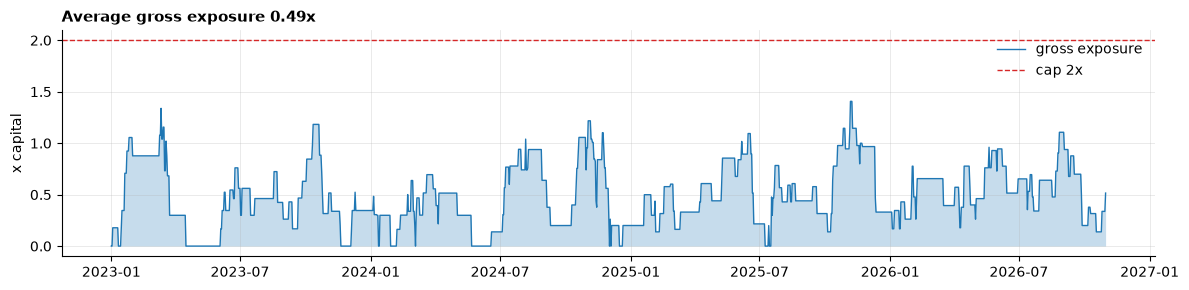

In [18]:
plots.plot_exposure(test_result.positions, params["max_gross_leverage"]);

## 6. Risk management: when to give up on a trade

Mean reversion fails when the ratio keeps moving *away* from normal. `strategy.apply_risk` checks these exit rules every day while a trade is open, in this order:

| Rule | Setting | In plain words |
|---|---|---|
| Back to normal | `exit_z` = 0 | The target: the ratio is back at its average, so take the profit |
| z-stop | `stop_z` = 4 | The ratio suddenly jumps extremely far (4 normal wiggles). Something has changed, so get out |
| Stop-loss | `stop_loss` = 0.10 | The trade has lost about 10% of its size since entry. This catches **slow trends**: the 90-day average drifts along with them, so z may never reach 4 while the losses still pile up |
| Take-profit | off | Not used, since the average is already the target |
| Time stop | 60 days | The ratio has not come back in 60 days, so it probably won't (section 2) |

**No chasing the same move.** After a stop, the pair stays out of the market until its entry signal switches off or flips to the other side. The same applies when an entry signal fires while z is already beyond 4.

**Portfolio limits.** Total exposure can never exceed 2× the capital (section 5). There is no "stop everything if we lose X%" rule. It would be one more setting tuned on limited history, so drawdowns are reported instead (section 8).

In [ ]:
print({k: params[k] for k in ("stop_z", "stop_loss", "take_profit", "time_stop_halflives", "max_holding_days")})
backtest.exit_reason_summary(test_result.trades)

**How trades ended on the test period:**

- **"Back to normal" exits work:** 51 trades, 98% of them winners, +\$67k in total.
- **Stop-losses wipe that out:** 61 trades (44% of all trades), −\$70k. Time stops (−\$10k) and z-stops (−\$5k) push the total below zero.
- **In one line:** the result is a tug-of-war between ratios that came back (many small wins) and ratios that kept trending (fewer but bigger losses), and the trends won.
- **Stops lose more than 10%.** Prices are checked only once a day and the exit happens a day later, so the price keeps moving in between. Stopped trades lost 12% on average (worst −28%), against the 10% limit.

## 7. How the backtest works

A **backtest** replays historical prices day by day and records what the strategy would have done and earned.

| Choice | Setting |
|---|---|
| Two periods | **Train** (`start → train_end`) is used for every design choice. **Test** (`train_end → end`) is run **once** at the end with frozen settings, like a final exam you haven't seen before |
| Warm-up | The 90-day averages at the start of each period use the days just before it (still only past data). Every period starts with no open trades |
| Calibration | Half-lives and volatilities (used for sizing and the time stop) are measured on train data only |
| Execution | Decide at day *t*'s close, trade at day *t+1*'s close |
| Profit calculation | Fixed dollar size per trade. The daily profit comes from the daily % change of both legs. No reinvesting of profits |
| Trading costs | Exchange fee (`fee_bps_per_leg` = 0.10%) plus slippage (`slippage_bps_per_leg` = 0.05%) on each leg, when opening and when closing. *Slippage* is getting a slightly worse price than quoted. A full round trip costs about 0.6% of the trade size |
| Shorting cost | `borrow_bps_per_day` = 0.03% per day (about 11% a year) on the sold leg. It stands in for the cost of borrowing a coin, or the funding rate on perpetual futures |
| Metrics | 365 trading days per year (crypto never closes), risk-free interest rate 0 |

In [16]:
pd.Series({k: v for k, v in setup.items() if k not in ("alts", "sweep_grid", "cost_multipliers")}, name="setup").to_frame()

,setup
source,yahoo
timeframe,1d
numeraire,BTC-USD
download_start,2017-11-09
start,2018-01-01
train_end,2023-01-01
end,2026-11-01
max_ffill_days,3
initial_capital,100000
fee_bps_per_leg,10


**Choosing settings without fooling ourselves.** If you try many settings and keep whichever happened to work best on past data, you are usually just picking up luck. This is called **overfitting**, and it tends to fail on new data. To limit it, 36 combinations (lookback window × entry level × stop-loss, from `setup.sweep_grid`) were tried once on **train data only**.

The heatmap shows the Sharpe ratio of each combination, with one panel per stop-loss level:

- **Every combination lost money on train.** Short windows (20 to 30 days) lose the most and longer windows lose less. This says that over days to weeks, alt/BTC ratios tend to *keep going* (trend) rather than come back.
- The chosen setting (90 days, entry at 2.0, stop-loss 0.10, Sharpe −0.08) is simply **the least bad**. The 90-day row is the best row in every panel, but the neighbouring entry levels are clearly worse (−0.54 and −0.67), so a small change would hurt. The result is **fragile**. It was kept as an honest baseline, and the test period played no part in choosing it.

In [ ]:
sweep = backtest.parameter_sweep(cfg, prices, setup["sweep_grid"], "train")
plots.plot_heatmap(sweep, x="entry_z", y="zscore_lookback", value="sharpe", facet="stop_loss");

**How much do trading costs matter?** (`backtest.cost_sensitivity`) The test period is rerun with all costs (fees, slippage and borrowing) scaled together: 0 = free trading, 1 = the assumed costs, 2 and 3 = double and triple.

In [ ]:
backtest.cost_sensitivity(cfg, prices, setup["cost_multipliers"], "test")[
    ["ann_return", "sharpe", "max_drawdown", "profit_factor"]
]

## 8. Results

The strategy compared with two simple alternatives that just buy and hold (`backtest.performance_table`):
- **buy_hold_btc**: put all the money into Bitcoin and hold it.
- **equal_weight_alts**: split the money equally across the ten alts and hold them.

One difference to keep in mind: the strategy uses fixed trade sizes and does not reinvest profits, while the buy-and-hold alternatives naturally grow with their gains (compounding).

**Reading the columns:** `ann_return` = return per year · `ann_vol` = how much it swings per year (risk) · `sharpe` = return per unit of risk · `sortino` = like Sharpe, but only counts downward swings · `max_drawdown` = worst fall from a high · `win_rate` = share of trades that made money · `profit_factor` = total won ÷ total lost (below 1 means losing overall) · `avg_trade_pnl` = average profit per trade in \$ · `avg_holding_bars` = average days a trade stays open.

In [ ]:
performance = backtest.performance_table({"train": train_result, "test": test_result}, cfg, prices)
performance[["total_return", "ann_return", "ann_vol", "sharpe", "sortino", "max_drawdown",
             "n_trades", "win_rate", "profit_factor", "avg_trade_pnl", "avg_holding_bars"]].astype(float)

**Account value over the test period.** Simply holding crypto beat the strategy by a wide margin.

It is not a fair fight in terms of risk, though. The strategy swings about 10% a year, while the buy-and-hold positions swing 46% to 56% a year, and this was a strong period for BTC. The chart shows what we gave up by not simply holding, not which approach is better per unit of risk.

In [ ]:
plots.plot_equity_curve({"strategy": test_result.equity, **backtest.benchmark_equity(cfg, prices, "test")});

The strategy on its own, on train and on test. Below it, the **drawdown** on the test period: at each moment, how far the account was below its previous high.

In [ ]:
plots.plot_equity_curve({"strategy, train": train_result.equity, "strategy, test": test_result.equity});
plots.plot_drawdown(test_result.equity);

Profit or loss per pair on the test period (`backtest.pnl_by_pair`):

In [ ]:
plots.plot_pnl_by_pair(backtest.pnl_by_pair(test_result.trades));

## 9. Looking at individual trades

Every completed trade in the test period, one row per trade:

| Column | Meaning |
|---|---|
| `direction` | +1 = bought the alt / sold BTC, −1 = sold the alt / bought BTC |
| `signal_time` | the day the rule fired |
| `entry_time`, `exit_time` | the days the trade actually opened and closed (one day after each signal) |
| `entry_z` | the z-score when the signal fired |
| `entry_ratio`, `exit_ratio` | alt/BTC when the trade opened and closed |
| `fair_ratio_at_entry` | the 90-day average ratio at entry: the "normal" we bet on returning to |
| `notional` | dollar size of each leg |
| `pnl`, `return`, `costs` | profit in \$ after all costs, the same as a % of `notional`, and the costs paid |
| `holding_bars` | days the trade was open |
| `exit_reason` | which rule closed it: `mean` (back to normal), `stop_loss`, `stop_z`, `time`, or `end` (still open when the data ran out) |

In [ ]:
trade_log = test_result.trades[[
    "pair", "direction", "signal_time", "entry_time", "exit_time", "entry_z", "entry_ratio",
    "fair_ratio_at_entry", "exit_ratio", "notional", "pnl", "return", "costs", "holding_bars", "exit_reason",
]]
trade_log

**Three trades up close.** They are picked automatically by a fixed rule (`backtest.pick_example_trades`), not by hand:
1. a **typical win**: the middle (median) trade among those closed by "back to normal",
2. the **best** trade,
3. the **worst** trade.

In each chart, the **top panel** shows the alt and BTC prices, both set to 1 at entry, so you can see which coin outran the other. The **bottom panel** shows z, with the signal (○), the entry and the exit marked.

In [ ]:
examples = backtest.pick_example_trades(test_result.trades)
examples[["example", "pair", "direction", "entry_time", "exit_time", "entry_z", "exit_z", "pnl", "return", "exit_reason"]]

In [ ]:
for _, trade in examples.iterrows():
    alt = trade["pair"].split("/")[0]
    d = test_pairs[alt].daily
    plots.plot_trade(prices.loc[d.index, alt], prices.loc[d.index, BTC], d["z"], trade, padding=30);

**What each one shows:**

- **Typical win: sell ADA / buy BTC, Oct 2026.** ADA got expensive compared with BTC (z = +2.1). The trade opened a day later and closed 11 days after that, when z crossed 0. Profit: +12.9% of the trade size, after about 0.6% in trading costs plus the daily borrowing cost.
- **Best trade: buy BCH / sell BTC, Feb–Mar 2024.** BCH was cheap (z = −2.1), then shot past normal all the way to z = +3.9 within 11 days. Profit: +49.5%. This single trade is the main reason BCH was the best pair.
- **Worst trade: buy LTC / sell BTC, Nov 2024.** LTC looked cheap (z = −2.0). Then BTC rallied about 30% in two weeks while LTC lagged behind. The 10% stop-loss fired on a daily close and the exit happened a day later, at −20.6%. Three weeks after the stop, LTC did outrun BTC: the stop was right to limit the risk but wrong about how things ended. Trades like this one decide the overall result.

## 10. Limitations: why to be cautious with these results

- **Markets change character.** There are long stretches where alts beat BTC for months ("alt season") and others where BTC dominates. Over 2018–2026, the data (train sweep and test result) says the ratios **trended more than they reverted** over a 3-to-13-week horizon. "Returns to normal" is not a reliable property of these ratios.
- **Survivorship bias.** We picked coins that are still big in 2026. Coins that collapsed against BTC are missing, and those are exactly the ones this strategy would have bought as "cheap" while they kept falling. Real results would likely be worse.
- **Data quality.** Yahoo gives one blended price per day at 00:00 UTC, not a price you could actually trade at on an exchange. There is no bid/ask or volume data, so slippage is a guess. Very low-priced coins (DOGE, TRX) show a few days with no price change at all, which is just rounding.
- **Shorting is not free or always possible.** Selling alts you don't own requires futures (perpetuals) or borrowing on margin. The real cost (the funding rate) varies a lot over time and between coins, while we use one flat number. Borrowing can also become unavailable exactly when everyone wants to short.
- **Stops only once a day.** Stops are checked on daily closes and executed a day later, so actual stop losses are bigger than the 10% limit (section 6). Tighter stops would need intraday data.
- **Simplified accounting.** The daily size adjustments are not charged, BTC legs across pairs are not netted, and there is no compounding.
- **Small sample.** 36 setting combinations on a single train period: even the least-bad one is partly fitted to that data. The test period has only about 140 trades.

## 11. Summary

| Question | Answer |
|---|---|
| What is traded? | Ten large altcoins, each priced against Bitcoin: ETH, BNB, XRP, ADA, DOGE, LTC, LINK, BCH, XLM, TRX. All have complete daily data since Nov 2017 |
| How long are trades? | Weeks. The ratio's gap from its 90-day average halves in 3 to 8 weeks. About 3.5 trades per pair per year (about 3 per month in total), each held 19 to 24 days on average |
| What does it look at? | The alt/BTC ratio (in logs), its 90-day average and normal wiggle size, the z-score, a fair value, the half-life, and ADF checks |
| When does it trade? | Sell alt / buy BTC when z > +2. Buy alt / sell BTC when z < −2. Close when z is back at 0. Each trade happens the day after the signal |
| How big? | Equal dollars on both legs, smaller positions for wilder pairs, at most 2× the capital in total |
| Safety exits | Close if z passes 4, if the trade loses about 10%, or after 60 days. No re-entry into the same move |
| How was it tested? | All decisions on 2018–2022 (train), then a single run on 2023–2026 (test). Fees, slippage and borrowing costs included |
| **Did it work?** | **No.** Test: −4.6% per year (Sharpe −0.44) after costs, +0.2% per year before costs. Train: −0.9% per year. Simply holding BTC made +49% per year over the test period |

**What we learned:** at a horizon of weeks, alt/BTC ratios tend to **keep trending rather than snap back**, so betting on a return to normal loses.

**Next steps:**
- Test the opposite bet (**momentum**: the trend continues) on train data, as a separate idea.
- Add a **trend filter** that skips pairs whose ratio is clearly trending.
- Use real, time-varying funding rates instead of a flat borrowing cost.
- Switch to exchange data with real bid/ask prices.